# Vocab Extension

### 1. Evaluate base tokenizer
- First i evaluated the base tokenizers of the llama3 models using the script 'compute_tokenizer_coverage.py'
- I collected the metrics for each language:
  - **Characters per token**
  - **Pieces per word**



In [1]:
import pandas as pd
base_tokenizer_csv_eval_path = "/scratch/hpc-prf-merlin/joel/moe-study/data_prep/metrics/tokenizer_metrics_llama3.2-1b_all_.csv"
df = pd.read_csv(base_tokenizer_csv_eval_path)
print("Best covered languages:")
print(df.nsmallest(15, "pieces_per_word")[["language", "pieces_per_word", "chars_per_token", "unknown_rate"]])

print("\n Worst covered languages:")
print(df.nlargest(5, "pieces_per_word")[["language", "pieces_per_word", "chars_per_token", "unknown_rate"]])

Best covered languages:
     language  pieces_per_word  chars_per_token  unknown_rate
197   english         1.312877         4.517402           0.0
195  spa_Latn         1.619902         3.740534           0.0
191  fas_Arab         1.658605         3.029692           0.0
100  nin_Latn         1.709528         2.516823           0.0
54   ile_Latn         1.717754         3.425544           0.0
78   lbb_Latn         1.782787         2.691116           0.0
32   csy_Latn         1.807866         2.718838           0.0
161  hin_Latn         1.815506         2.886623           0.0
139  xmm_Latn         1.866019         2.983659           0.0
106  jbo_Latn         1.878802         2.577222           0.0
115  nii_Latn         1.918645         2.618079           0.0
26   ibg_Latn         1.997961         3.040667           0.0
126  whg_Latn         2.000003         2.813174           0.0
141  mww_Latn         2.005804         2.474800           0.0
77   lgl_Latn         2.008272         2.47729

Note: llama3 uses a Byte-Pair Encoding tokenizer without an unknown token id. It brekas words into subwords units learned from training data. Every text is a combination of known byte sequences. Therefore it never encounters a token it cant represent


In [2]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained("meta-llama/Llama-3.2-1B", use_fast=True)
print("unk_token:", tokenizer.unk_token)
print("unk_token_id:", tokenizer.unk_token_id)


/scratch/hpc-prf-merlin/joel/htyllm-pg/joel/conda/envs/moe-study/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


unk_token: None
unk_token_id: None


### 2. Determine how many vocabs to extend for each language
Since we see aboove that langauges such as 'dzo_Tibt' are extremely bad while others such as english are quite well in performanmce. 
We calcaulte the number of tokens we want to add for each langauge depending on its performance

In [3]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler

TOTAL_NEW_TOKENS = 128_000
W_PPW, W_CPT, W_UNK = 0.5, 0.5, 0.0
factor = 2.0

df = pd.read_csv(base_tokenizer_csv_eval_path)
print(f"Loaded tokenizer metrics for {len(df)} languages.\n")

scaler = MinMaxScaler()
df["ppw_n"] = scaler.fit_transform(df[["pieces_per_word"]])
df["cpt_n"] = 1 - scaler.fit_transform(df[["chars_per_token"]])
df["unk_n"] = scaler.fit_transform(df[["unknown_rate"]])

print("Normalized metrics preview:")
print(df[["language", "ppw_n", "cpt_n", "unk_n"]].head(), "\n")

# --- Linear inefficiency ---
df["I_lin"] = W_PPW*df["ppw_n"] + W_CPT*df["cpt_n"] + W_UNK*df["unk_n"]
print("Computed linear inefficiency scores:")
print(df[["language", "I_lin"]].head(), "\n")

# --- Nonlinear emphasis ---
nonlinear = df["I_lin"] ** factor
df["inefficiency_score"] = MinMaxScaler().fit_transform(nonlinear.to_numpy().reshape(-1, 1))

print(f"Applied nonlinear scaling (factor = {factor}).")
df = df.sort_values("inefficiency_score", ascending=False)
print(df[["language", "pieces_per_word", "chars_per_token", "inefficiency_score"]].head(10), "\n")

# --- Allocate tokens proportionally ---
w = df["inefficiency_score"].to_numpy()
ideal = w / w.sum() * TOTAL_NEW_TOKENS
alloc = np.floor(ideal).astype(int)
shortfall = TOTAL_NEW_TOKENS - alloc.sum()
alloc[np.argsort(-(ideal - alloc))[:shortfall]] += 1
df["token_alloc"] = alloc

assert df["token_alloc"].sum() == TOTAL_NEW_TOKENS
print(f"Sum of allocated tokens: {df['token_alloc'].sum()} (target = {TOTAL_NEW_TOKENS})\n")

print("Top 10 token allocations:")
print(df.sort_values('token_alloc', ascending=False)[["language", "token_alloc"]].head(10))


Loaded tokenizer metrics for 200 languages.

Normalized metrics preview:
   language     ppw_n     cpt_n  unk_n
0  bwq_Latn  0.040174  0.642849    0.0
1  dty_Deva  0.060083  0.676100    0.0
2  ayo_Latn  0.025675  0.496672    0.0
3  cho_Latn  0.044767  0.567305    0.0
4  enx_Latn  0.052342  0.565282    0.0 

Computed linear inefficiency scores:
   language     I_lin
0  bwq_Latn  0.341512
1  dty_Deva  0.368092
2  ayo_Latn  0.261173
3  cho_Latn  0.306036
4  enx_Latn  0.308812 

Applied nonlinear scaling (factor = 2.0).
     language  pieces_per_word  chars_per_token  inefficiency_score
155  dzo_Tibt        38.736257         0.535776            1.000000
159  ksw_Mymr        33.332568         0.512968            0.864095
150  lao_Laoo        27.993365         0.563407            0.724107
140  wuu_Hani        23.361391         1.194428            0.504202
176  ory_Orya        15.474431         0.417294            0.489036
179  ojb_Cans        13.632081         0.423856            0.453634
18

In [4]:
print("\nBest 15 languages with highest token allocation:")
print(df[["language", "inefficiency_score", "token_alloc"]].head(15))

print("\nWorst 10 (best-covered) languages:")
print(df[["language", "inefficiency_score", "token_alloc"]].tail(10))



Best 15 languages with highest token allocation:
     language  inefficiency_score  token_alloc
155  dzo_Tibt            1.000000         4777
159  ksw_Mymr            0.864095         4128
150  lao_Laoo            0.724107         3459
140  wuu_Hani            0.504202         2409
176  ory_Orya            0.489036         2336
179  ojb_Cans            0.453634         2167
189  kat_Geor            0.452850         2163
162  sat_Olck            0.442255         2113
166  tzm_Tfng            0.421262         2012
196  tel_Telu            0.414217         1979
110  tig_Ethi            0.412181         1969
53   crl_Cans            0.404356         1932
183  tcy_Knda            0.403578         1928
198  syc_Syrc            0.391562         1871
142  wsg_Telu            0.381945         1825

Worst 10 (best-covered) languages:
     language  inefficiency_score  token_alloc
129  pam_Latn            0.042311          202
139  xmm_Latn            0.038918          186
26   ibg_Latn        

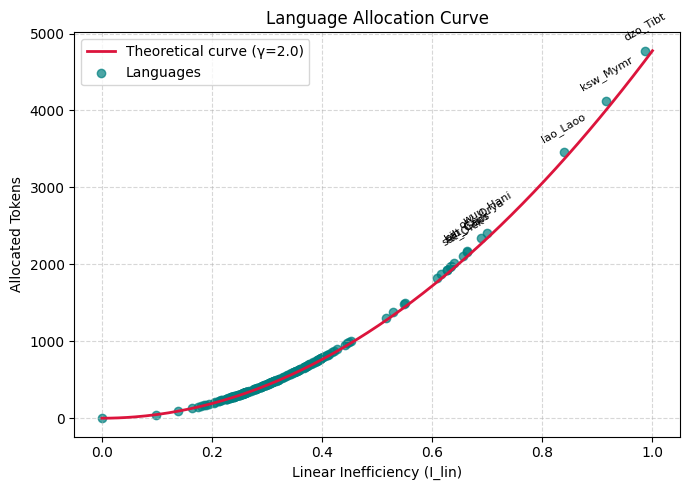

In [5]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(0, 1, 200)
y = x ** factor

plt.figure(figsize=(7, 5))

# theoretical mapping
plt.plot(x, y / y.max() * df["token_alloc"].max(),  # scale to same range as tokens
         color="crimson", linewidth=2, label=f"Theoretical curve (γ={factor})")
plt.scatter(df["I_lin"], df["token_alloc"], color="teal", alpha=0.7, label="Languages")

# Annotate top 8 languages
for _, row in df.nlargest(8, "token_alloc").iterrows():
    plt.text(row["I_lin"], row["token_alloc"] + (0.02 * df["token_alloc"].max()),
             row["language"], ha="center", va="bottom", fontsize=8, rotation=30)

plt.title("Language Allocation Curve")
plt.xlabel("Linear Inefficiency (I_lin)")
plt.ylabel("Allocated Tokens")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()


we save these results in 'data_prep/metrics/vocab_extension_plan_ranking_based_all_llama_3.2-1b.csv'

In [6]:
output_path = "/scratch/hpc-prf-merlin/joel/moe-study/data_prep/metrics/vocab_extension_plan_ranking_based_all_llama_3.2-1b.csv"
df.to_csv(output_path, index=False)
print(f"\nSaved results to: {output_path}")


Saved results to: /scratch/hpc-prf-merlin/joel/moe-study/data_prep/metrics/vocab_extension_plan_ranking_based_all_llama_3.2-1b.csv


### 3. Extend the base tokenizer
Lastly we extend the base tokenizer by the 'token_alloc' values of the resulting csv

1. We load sample data in each langauge and tokenize it with the multilingual tokenizer
2. Check how frequently the tokens occur in the test data
3. Select the most frequent tokens which are not in the base tokenizer as candidates for new tokens. From these candidates take the tok k depending on the 'token_alloc' value form the csv
4. Add these tokens to the base tokenizer’s vocabulary.
5. Import corresponding BPE merges from the multilingual tokenizer for those tokens and append any valid ones to the base tokenizer’s merge list.

all of this is done in the 'extend_tok_most_important.py'

### 4. Eval and compare the new tokenizer

In [7]:
import pandas as pd

df_base = pd.read_csv("/scratch/hpc-prf-merlin/joel/moe-study/data_prep/metrics/tokenizer_metrics_llama3.2-1b_all_.csv")
df_new = pd.read_csv("/scratch/hpc-prf-merlin/joel/moe-study/data_prep/temp/merged_extended_tokenizer/test_tokenizer_coverage.csv")

df_base = df_base.rename(columns={
    "pieces_per_word": "ppw_base",
    "chars_per_token": "cpt_base",
    "unknown_rate": "unk_base"
})
df_new = df_new.rename(columns={
    "pieces_per_word": "ppw_new",
    "chars_per_token": "cpt_new",
    "unknown_rate": "unk_new"
})

df_cmp = pd.merge(df_base, df_new, on="language", how="inner")
df_cmp["ppw_diff"] = df_cmp["ppw_base"] - df_cmp["ppw_new"]
df_cmp["cpt_diff"] = df_cmp["cpt_new"] - df_cmp["cpt_base"]
df_cmp["unk_diff"] = df_cmp["unk_base"] - df_cmp["unk_new"]

print("Top 15 languages with biggest PPW improvement:")
print(df_cmp.sort_values("ppw_diff", ascending=False)[
    ["language", "ppw_base", "ppw_new", "ppw_diff", "cpt_base", "cpt_new", "cpt_diff"]
].head(15))


Top 15 languages with biggest PPW improvement:
     language   ppw_base   ppw_new   ppw_diff  cpt_base   cpt_new  cpt_diff
155  dzo_Tibt  38.736257  9.999919  28.736338  0.535776  2.101609  1.565833
159  ksw_Mymr  33.332568  8.541757  24.790811  0.512968  1.989612  1.476643
150  lao_Laoo  27.993365  7.013813  20.979553  0.563407  2.257639  1.694232
176  ory_Orya  15.474431  3.449160  12.025270  0.417294  1.872995  1.455700
189  kat_Geor  14.815406  2.997362  11.818044  0.558206  2.758847  2.200641
162  sat_Olck  13.106978  2.600635  10.506343  0.435029  2.191784  1.756754
179  ojb_Cans  13.632081  3.347766  10.284315  0.423856  1.724665  1.300809
110  tig_Ethi  11.320000  1.280000  10.040000  0.425206  3.760417  3.335211
196  tel_Telu  13.025482  4.000554   9.024929  0.599254  1.948796  1.349542
198  syc_Syrc  11.355129  2.467566   8.887563  0.560492  2.599121  2.038629
166  tzm_Tfng  12.130776  3.354019   8.776757  0.457184  1.657092  1.199908
183  tcy_Knda  12.386649  3.929908   8.45

In [8]:
print("\n \n15 languages with smallest PPW improvement:")
print(df_cmp.sort_values("ppw_diff", ascending=False)[
    ["language", "ppw_base", "ppw_new", "ppw_diff", "cpt_base", "cpt_new", "cpt_diff"]
].tail(10))


 
15 languages with smallest PPW improvement:
     language  ppw_base   ppw_new  ppw_diff  cpt_base   cpt_new  cpt_diff
26   ibg_Latn  1.997961  1.623578  0.374383  3.040667  3.740452  0.699786
168  snd_Deva  3.026219  2.661552  0.364668  1.700673  1.934700  0.234027
154  srd_Latn  2.097065  1.785318  0.311747  2.859240  3.364598  0.505358
106  jbo_Latn  1.878802  1.585954  0.292849  2.577222  3.082017  0.504795
108  arz_Arab  2.228510  1.944938  0.283572  2.475029  2.851663  0.376634
191  fas_Arab  1.658605  1.398804  0.259800  3.029692  3.601737  0.572046
54   ile_Latn  1.717754  1.542928  0.174827  3.425544  3.803689  0.378144
195  spa_Latn  1.619902  1.451968  0.167934  3.740534  4.183041  0.442507
184  hin_Deva  2.575818  2.491182  0.084636  1.962438  2.031186  0.068748
197   english  1.312877  1.307867  0.005010  4.517402  4.531794  0.014392


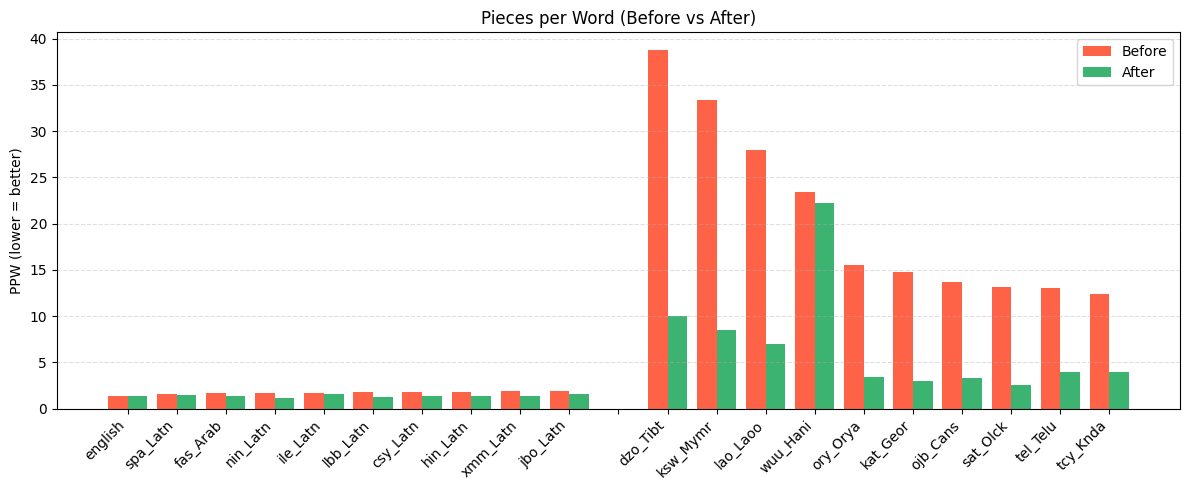

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

df_b = pd.read_csv("/scratch/hpc-prf-merlin/joel/moe-study/data_prep/metrics/tokenizer_metrics_llama3.2-1b_all_.csv")[["language", "pieces_per_word"]].rename(columns={"pieces_per_word": "ppw_base"})
df_n = pd.read_csv("/scratch/hpc-prf-merlin/joel/moe-study/data_prep/temp/merged_extended_tokenizer/test_tokenizer_coverage.csv")[["language", "pieces_per_word"]].rename(columns={"pieces_per_word": "ppw_new"})
df = pd.merge(df_b, df_n, on="language")

top, bottom = df.nsmallest(10, "ppw_base"), df.nlargest(10, "ppw_base")
dfv = pd.concat([top, pd.DataFrame({"language": [" "], "ppw_base": [np.nan], "ppw_new": [np.nan]}), bottom], ignore_index=True)

x = np.arange(len(dfv)); w = 0.4
plt.figure(figsize=(12, 5))
plt.bar(x - w/2, dfv["ppw_base"], w, color="tomato", label="Before")
plt.bar(x + w/2, dfv["ppw_new"], w, color="mediumseagreen", label="After")
plt.xticks(x, dfv["language"], rotation=45, ha="right")
plt.title("Pieces per Word (Before vs After)")
plt.ylabel("PPW (lower = better)")
plt.legend(); plt.grid(axis="y", ls="--", alpha=0.4); plt.tight_layout(); plt.show()


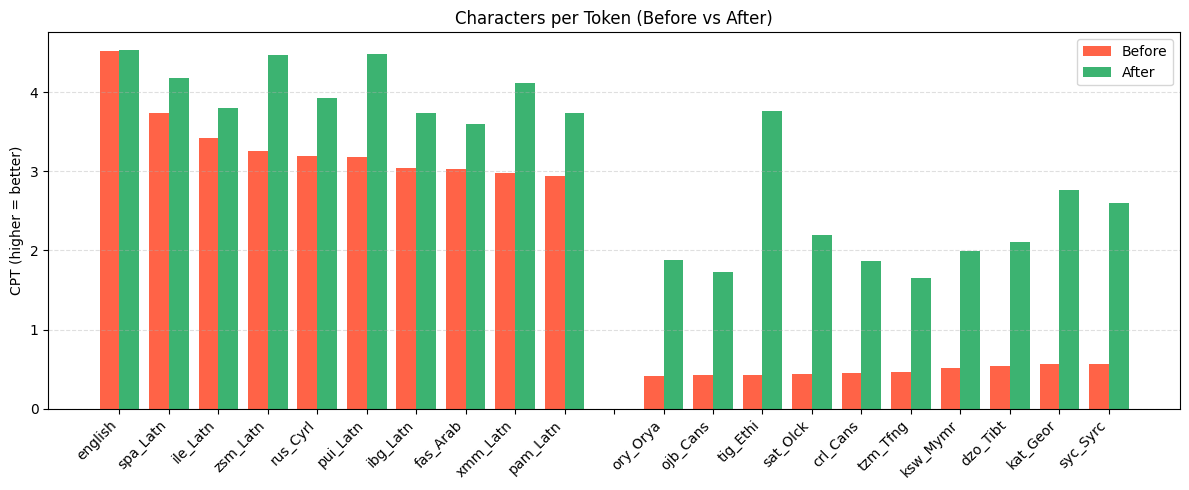

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

df_b = pd.read_csv("/scratch/hpc-prf-merlin/joel/moe-study/data_prep/metrics/tokenizer_metrics_llama3.2-1b_all_.csv")[["language", "chars_per_token"]].rename(columns={"chars_per_token": "cpt_base"})
df_n = pd.read_csv("/scratch/hpc-prf-merlin/joel/moe-study/data_prep/temp/merged_extended_tokenizer/test_tokenizer_coverage.csv")[["language", "chars_per_token"]].rename(columns={"chars_per_token": "cpt_new"})
df = pd.merge(df_b, df_n, on="language")

top, bottom = df.nlargest(10, "cpt_base"), df.nsmallest(10, "cpt_base")  # reversed because higher = better
dfv = pd.concat([top, pd.DataFrame({"language": [" "], "cpt_base": [np.nan], "cpt_new": [np.nan]}), bottom], ignore_index=True)

x = np.arange(len(dfv)); w = 0.4
plt.figure(figsize=(12, 5))
plt.bar(x - w/2, dfv["cpt_base"], w, color="tomato", label="Before")
plt.bar(x + w/2, dfv["cpt_new"], w, color="mediumseagreen", label="After")
plt.xticks(x, dfv["language"], rotation=45, ha="right")
plt.title("Characters per Token (Before vs After)")
plt.ylabel("CPT (higher = better)")
plt.legend(); plt.grid(axis="y", ls="--", alpha=0.4); plt.tight_layout(); plt.show()


In [11]:
from transformers import AutoTokenizer

base_path = "/scratch/hpc-prf-merlin/shared_cache/huggingface/models--meta-llama--Llama-3.2-1B/snapshots/4e20de362430cd3b72f300e6b0f18e50e7166e08/"
extended_path = "/scratch/hpc-prf-merlin/joel/moe-study/data_prep/temp/merged_extended_tokenizer/"

base_tok = AutoTokenizer.from_pretrained(base_path, use_fast=True)
ext_tok = AutoTokenizer.from_pretrained(extended_path, use_fast=True)

print(f"Base tokenizer vocab size:     {len(base_tok.get_vocab()):,}")
print(f"Extended tokenizer vocab size: {len(ext_tok.get_vocab()):,}")
print(f"Tokens added:                  {len(ext_tok.get_vocab()) - len(base_tok.get_vocab()):,}")


Base tokenizer vocab size:     128,256
Extended tokenizer vocab size: 248,737
Tokens added:                  120,481
